In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

In [3]:
import os

print(os.getcwd())

C:\Users\Biswajit Mandal\AI-Powered Fake Job Posting Detection and risk Assessment System\ Code


In [4]:
import os

print(os.listdir())

[' eda_US.ipynb', ' model.ipynb', '.ipynb_checkpoints', 'Untitled.ipynb']


In [5]:
import os

print(os.path.exists("data"))

False


In [6]:
import os

project_path = r"C:\Users\Biswajit Mandal\AI-Powered Fake Job Posting Detection and risk Assessment System"

for root, dirs, files in os.walk(project_path):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

C:\Users\Biswajit Mandal\AI-Powered Fake Job Posting Detection and risk Assessment System\ Data\fake_job_postings.csv
C:\Users\Biswajit Mandal\AI-Powered Fake Job Posting Detection and risk Assessment System\ Data\fake_job_postings_cleaned.csv
C:\Users\Biswajit Mandal\AI-Powered Fake Job Posting Detection and risk Assessment System\ Data\spellings.csv


In [10]:
import pandas as pd

fake_job_postings = pd.read_csv(
    r"C:\Users\Biswajit Mandal\AI-Powered Fake Job Posting Detection and risk Assessment System\ Data\fake_job_postings_cleaned.csv"
)

print("Dataset loaded successfully!")
print("Shape:", fake_job_postings.shape)

Dataset loaded successfully!
Shape: (10593, 6)


In [11]:
print(fake_job_postings.columns.tolist())

['Unnamed: 0', 'telecommuting', 'fraudulent', 'ratio', 'text', 'character_count']


In [12]:
fake_job_postings.head()

,Unnamed: 0,telecommuting,fraudulent,ratio,text,character_count
0,0,0,0,0.03,"Marketing Intern US, NY, New York We're Food52...",2705
1,1,0,0,0.03,"Visual Designer US, NY, New York Kettle is an ...",1991
2,2,0,0,0.03,"Payroll Tax Specialist US, NY, New York Namely...",1564
3,3,0,0,0.03,"Marketing Manager US, NY, New York Super Socce...",2871
4,4,0,0,0.03,"English Teacher Abroad US, NY, New York We hel...",669


In [13]:
print(fake_job_postings.isnull().sum())

Unnamed: 0         0
telecommuting      0
fraudulent         0
ratio              0
text               0
character_count    0
dtype: int64


In [14]:
print("Duplicate rows:", fake_job_postings.duplicated().sum())

Duplicate rows: 0


In [16]:
numeric_data = fake_job_postings.select_dtypes(include="number")

corr = numeric_data.corr()

print(corr)

                 Unnamed: 0  telecommuting  fraudulent     ratio  \
Unnamed: 0         1.000000      -0.044502    0.091797  0.007010   
telecommuting     -0.044502       1.000000    0.038015 -0.012546   
fraudulent         0.091797       0.038015    1.000000  0.281244   
ratio              0.007010      -0.012546    0.281244  1.000000   
character_count   -0.113319       0.008225   -0.089340  0.013601   

                 character_count  
Unnamed: 0             -0.113319  
telecommuting           0.008225  
fraudulent             -0.089340  
ratio                   0.013601  
character_count         1.000000  


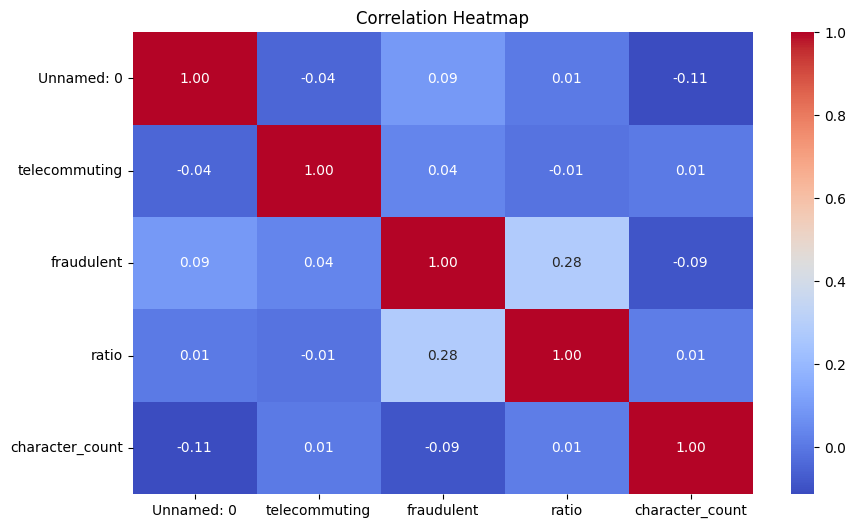

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [18]:
fake_job_postings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10593 entries, 0 to 10592
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       10593 non-null  int64  
 1   telecommuting    10593 non-null  int64  
 2   fraudulent       10593 non-null  int64  
 3   ratio            10593 non-null  float64
 4   text             10593 non-null  object 
 5   character_count  10593 non-null  int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 496.7+ KB


In [19]:
fake_job_postings.describe()

,Unnamed: 0,telecommuting,fraudulent,ratio,character_count
count,10593.000000,10593.000000,10593.000000,10593.000000,10593.000000
mean,5296.000000,0.049561,0.068441,0.123056,2730.846597
std,3058.080035,0.217046,0.252514,0.941099,1491.440984
min,0.000000,0.000000,0.000000,0.000000,95.000000
25%,2648.000000,0.000000,0.000000,0.000000,1584.000000
50%,5296.000000,0.000000,0.000000,0.010000,2635.000000
75%,7944.000000,0.000000,0.000000,0.040000,3588.000000
max,10592.000000,1.000000,1.000000,15.000000,14989.000000


In [20]:
print(fake_job_postings["fraudulent"].value_counts())

fraudulent
0    9868
1     725
Name: count, dtype: int64


In [21]:
print(
    fake_job_postings["fraudulent"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

fraudulent
0    93.16
1     6.84
Name: proportion, dtype: float64


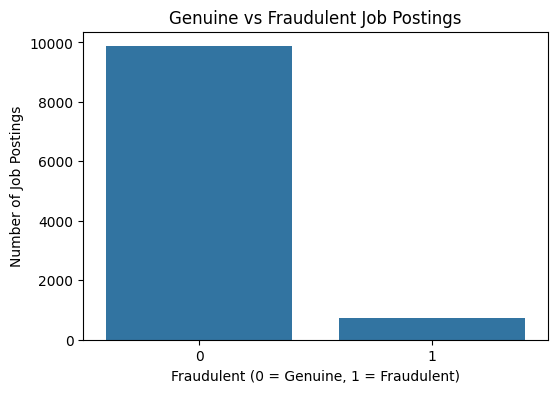

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(
    data=fake_job_postings,
    x="fraudulent"
)

plt.title("Genuine vs Fraudulent Job Postings")
plt.xlabel("Fraudulent (0 = Genuine, 1 = Fraudulent)")
plt.ylabel("Number of Job Postings")

plt.show()

In [23]:
missing_values = fake_job_postings.isnull().sum()

print(missing_values)

Unnamed: 0         0
telecommuting      0
fraudulent         0
ratio              0
text               0
character_count    0
dtype: int64


In [24]:
print("Duplicate rows:", fake_job_postings.duplicated().sum())

Duplicate rows: 0


In [25]:
numeric_data = fake_job_postings.select_dtypes(include="number")

corr = numeric_data.corr()

print(corr)

                 Unnamed: 0  telecommuting  fraudulent     ratio  \
Unnamed: 0         1.000000      -0.044502    0.091797  0.007010   
telecommuting     -0.044502       1.000000    0.038015 -0.012546   
fraudulent         0.091797       0.038015    1.000000  0.281244   
ratio              0.007010      -0.012546    0.281244  1.000000   
character_count   -0.113319       0.008225   -0.089340  0.013601   

                 character_count  
Unnamed: 0             -0.113319  
telecommuting           0.008225  
fraudulent             -0.089340  
ratio                   0.013601  
character_count         1.000000  


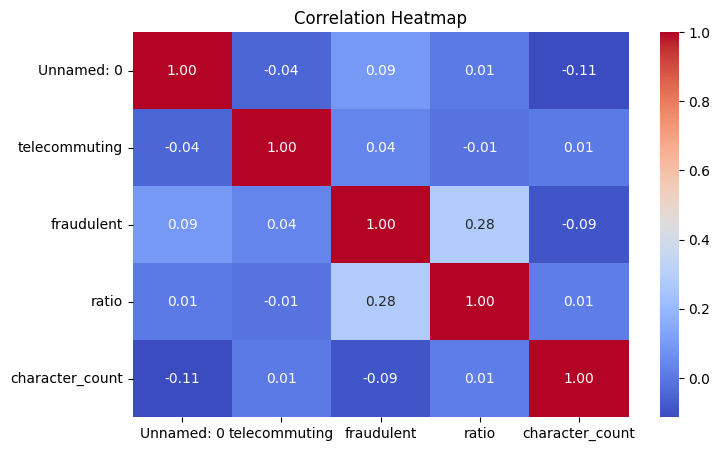

In [26]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [27]:
import pandas as pd

fake_job_postings = pd.read_csv(
    r"C:\Users\Biswajit Mandal\AI-Powered Fake Job Posting Detection and risk Assessment System\ Data\fake_job_postings_cleaned.csv"
)

print("Dataset loaded successfully!")
print("Shape:", fake_job_postings.shape)

Dataset loaded successfully!
Shape: (10593, 6)


In [29]:
# ==========================================
# Load Fake Job Posting Dataset
# ==========================================

import pandas as pd

file_path = r"C:\Users\Biswajit Mandal\AI-Powered Fake Job Posting Detection and risk Assessment System\ Data\fake_job_postings_cleaned.csv"

fake_job_postings = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", fake_job_postings.shape)
print("Columns:", fake_job_postings.columns.tolist())

Dataset loaded successfully!
Dataset shape: (10593, 6)
Columns: ['Unnamed: 0', 'telecommuting', 'fraudulent', 'ratio', 'text', 'character_count']


In [30]:
fake_job_postings.head()

,Unnamed: 0,telecommuting,fraudulent,ratio,text,character_count
0,0,0,0,0.03,"Marketing Intern US, NY, New York We're Food52...",2705
1,1,0,0,0.03,"Visual Designer US, NY, New York Kettle is an ...",1991
2,2,0,0,0.03,"Payroll Tax Specialist US, NY, New York Namely...",1564
3,3,0,0,0.03,"Marketing Manager US, NY, New York Super Socce...",2871
4,4,0,0,0.03,"English Teacher Abroad US, NY, New York We hel...",669


In [31]:
fake_job_postings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10593 entries, 0 to 10592
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       10593 non-null  int64  
 1   telecommuting    10593 non-null  int64  
 2   fraudulent       10593 non-null  int64  
 3   ratio            10593 non-null  float64
 4   text             10593 non-null  object 
 5   character_count  10593 non-null  int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 496.7+ KB


In [32]:
X = fake_job_postings[['telecommuting', 'ratio', 'text', 'character_count']]
y = fake_job_postings['fraudulent']

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=53)

In [34]:
X_train_num = X_train[['telecommuting', 'ratio', 'character_count']]
X_test_num = X_test[['telecommuting', 'ratio', 'character_count']]

In [35]:
count_vectorizer = CountVectorizer(stop_words='english')
count_train = count_vectorizer.fit_transform(X_train.text.values)
count_test = count_vectorizer.transform(X_test.text.values)

In [36]:
tfidf_vectorizer = TfidfVectorizer(stop_words="english", max_df=1)
tfidf_train = tfidf_vectorizer.fit_transform(X_train.text)
tfidf_test = tfidf_vectorizer.transform(X_test.text)

In [37]:
from sklearn.naive_bayes import MultinomialNB
from sklearn import metrics
from sklearn.model_selection import train_test_split

nb_classifier = MultinomialNB()
nb_classifier.fit(count_train, y_train)
pred = nb_classifier.predict(count_test)
metrics.accuracy_score(y_test, pred)

0.971395881006865

In [38]:
metrics.f1_score(y_test, pred)

0.7435897435897436

In [40]:
from sklearn.linear_model import SGDClassifier
from sklearn import metrics

clf_log = SGDClassifier(
    loss='log_loss',
    random_state=42
)

clf_log.fit(count_train, y_train)

pred_log = clf_log.predict(count_test)

accuracy = metrics.accuracy_score(y_test, pred_log)

print("Accuracy:", accuracy)

Accuracy: 0.9759725400457666


In [44]:
print("Accuracy: {:.2f}%".format(accuracy * 100))

Accuracy: 97.60%


In [45]:
print(metrics.classification_report(y_test, pred_log))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99      3265
           1       0.86      0.77      0.81       231

    accuracy                           0.98      3496
   macro avg       0.92      0.88      0.90      3496
weighted avg       0.98      0.98      0.98      3496



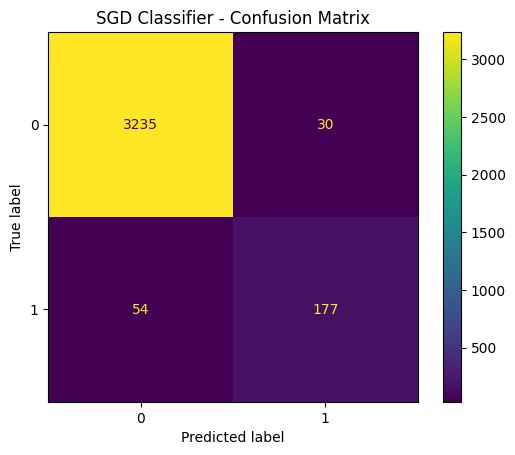

In [46]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_log
)

plt.title("SGD Classifier - Confusion Matrix")
plt.show()

In [47]:
from sklearn.linear_model import SGDClassifier
from sklearn import metrics

clf_num = SGDClassifier(
    loss='log_loss',
    random_state=42
)

clf_num.fit(X_train_num, y_train)

pred_num = clf_num.predict(X_test_num)

accuracy_num = metrics.accuracy_score(y_test, pred_num)

print("Accuracy:", accuracy_num)
print("Accuracy: {:.2f}%".format(accuracy_num * 100))

Accuracy: 0.9339244851258581
Accuracy: 93.39%


In [48]:
print(metrics.classification_report(y_test, pred_num))

              precision    recall  f1-score   support

           0       0.93      1.00      0.97      3265
           1       0.00      0.00      0.00       231

    accuracy                           0.93      3496
   macro avg       0.47      0.50      0.48      3496
weighted avg       0.87      0.93      0.90      3496



C:\Users\Biswajit Mandal\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Biswajit Mandal\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Biswajit Mandal\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


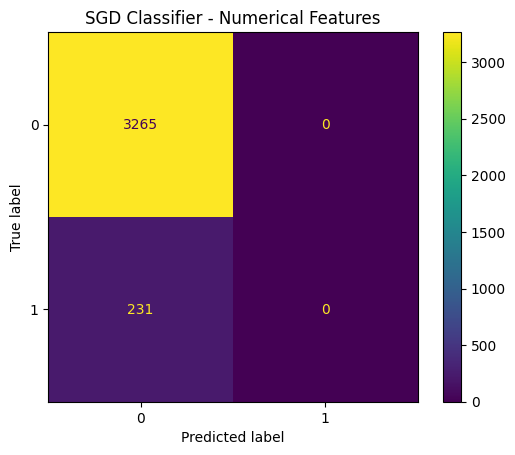

In [49]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_num
)

plt.title("SGD Classifier - Numerical Features")
plt.show()

In [50]:
SGDClassifier(loss='log')

SGDClassifier(loss='log')

In [51]:
SGDClassifier(loss='log_loss')

SGDClassifier(loss='log_loss')

In [52]:
clf_log = SGDClassifier(loss='log_loss')

In [53]:
clf_num = SGDClassifier(loss='log_loss')

In [54]:
prediction_array = []

for i, j in zip(pred_num, pred_log):
    if i == 0 and j == 0:
        prediction_array.append(0)
    else:
        prediction_array.append(1)

In [55]:
metrics.accuracy_score(y_test, prediction_array)

0.9759725400457666

In [56]:
metrics.f1_score(y_test, prediction_array)

0.8082191780821918

In [57]:
from sklearn.metrics import confusion_matrix

cf_matrix = confusion_matrix(y_test, prediction_array)

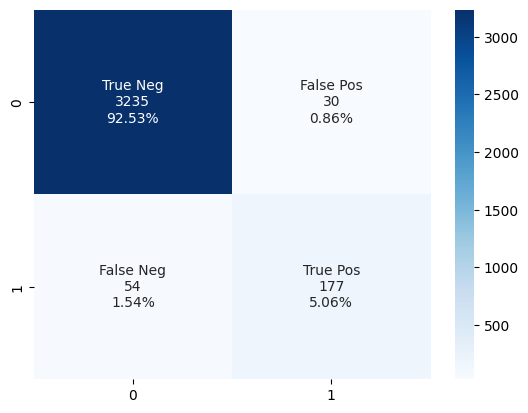

In [58]:
group_names = ["True Neg","False Pos", "False Neg", "True Pos"]
group_counts = ["{0:0.0f}".format(value) for value in
                cf_matrix.flatten()]
group_percentages = ["{0:.2%}".format(value) for value in
                      cf_matrix.flatten()/np.sum(cf_matrix)]
labels = [f'{v1}\n{v2}\n{v3}' for v1, v2, v3 in
          zip(group_names,group_counts,group_percentages)]
labels = np.asarray(labels).reshape(2,2)
sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues');

In [59]:
len(y_test[y_test == 0]), len(y_test[y_test == 1])

(3265, 231)